O serviço de vendas de carros usados Rusty Bargain está desenvolvendo um aplicativo para atrair novos clientes. Nesse aplicativo, você pode descobrir rapidamente o valor de mercado do seu carro. Você tem acesso a dados históricos: especificações técnicas, versões de acabamento e preços. Você precisa construir o modelo para determinar o valor. 

Rusty Bargain está interessado em:

- a qualidade da predição;
- a velocidade da predição;
- o tempo necessário para o treinamento

## Importação das bibliotecas

In [1]:
import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import OrdinalEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import time

Nesta etapa foram importadas todas as bibliotecas necessárias para análise dos dados, treinamento dos modelos, cálculo das métricas e medição do tempo de execução.

## Carregando os dados

In [2]:
df = pd.read_csv('/datasets/car_data.csv')

#Primeira análise
df.head()

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,24/03/2016 11:52,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,24/03/2016 00:00,0,70435,07/04/2016 03:16
1,24/03/2016 10:58,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,24/03/2016 00:00,0,66954,07/04/2016 01:46
2,14/03/2016 12:52,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,14/03/2016 00:00,0,90480,05/04/2016 12:47
3,17/03/2016 16:54,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,17/03/2016 00:00,0,91074,17/03/2016 17:40
4,31/03/2016 17:25,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,31/03/2016 00:00,0,60437,06/04/2016 10:17


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Mileage            354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  NotRepaired        283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

In [4]:
df.describe()

,Price,RegistrationYear,Power,Mileage,RegistrationMonth,NumberOfPictures,PostalCode
count,354369.000000,354369.000000,354369.000000,354369.000000,354369.000000,354369.0,354369.000000
mean,4416.656776,2004.234448,110.094337,128211.172535,5.714645,0.0,50508.689087
std,4514.158514,90.227958,189.850405,37905.341530,3.726421,0.0,25783.096248
min,0.000000,1000.000000,0.000000,5000.000000,0.000000,0.0,1067.000000
25%,1050.000000,1999.000000,69.000000,125000.000000,3.000000,0.0,30165.000000
50%,2700.000000,2003.000000,105.000000,150000.000000,6.000000,0.0,49413.000000
75%,6400.000000,2008.000000,143.000000,150000.000000,9.000000,0.0,71083.000000
max,20000.000000,9999.000000,20000.000000,150000.000000,12.000000,0.0,99998.000000


In [5]:
df.sample(5)

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
346567,29/03/2016 17:51,300,wagon,1998,manual,0,other,150000,7,petrol,fiat,no,29/03/2016 00:00,0,69181,06/04/2016 03:45
270770,17/03/2016 13:38,899,sedan,1998,manual,116,mondeo,125000,7,petrol,ford,no,17/03/2016 00:00,0,76297,06/04/2016 16:45
343448,04/04/2016 18:39,8450,bus,2002,manual,102,transporter,150000,2,gasoline,volkswagen,no,04/04/2016 00:00,0,28876,06/04/2016 20:44
42120,22/03/2016 00:25,600,small,1998,auto,60,polo,125000,11,petrol,volkswagen,no,21/03/2016 00:00,0,60435,23/03/2016 21:29
204039,01/04/2016 15:25,9780,suv,2012,manual,122,yeti,125000,6,petrol,skoda,no,01/04/2016 00:00,0,56288,07/04/2016 09:44


Foi realizada uma inspeção inicial para conhecer a estrutura do conjunto de dados, identificar tipos de variáveis e verificar possíveis problemas de qualidade.

## Preparação de Dados

In [6]:
# valores ausente 
df.isna().sum()

DateCrawled              0
Price                    0
VehicleType          37490
RegistrationYear         0
Gearbox              19833
Power                    0
Model                19705
Mileage                  0
RegistrationMonth        0
FuelType             32895
Brand                    0
NotRepaired          71154
DateCreated              0
NumberOfPictures         0
PostalCode               0
LastSeen                 0
dtype: int64

In [7]:
# Se existirem:
df['VehicleType'].fillna('Unknown', inplace=True)
df['Gearbox'].fillna('Unknown', inplace=True)
df['Model'].fillna('Unknown', inplace=True)
df['FuelType'].fillna('Unknown', inplace=True)
df['NotRepaired'].fillna('Unknown', inplace=True)
print(df.head(5))

        DateCrawled  Price VehicleType  RegistrationYear Gearbox  Power  \
0  24/03/2016 11:52    480     Unknown              1993  manual      0   
1  24/03/2016 10:58  18300       coupe              2011  manual    190   
2  14/03/2016 12:52   9800         suv              2004    auto    163   
3  17/03/2016 16:54   1500       small              2001  manual     75   
4  31/03/2016 17:25   3600       small              2008  manual     69   

     Model  Mileage  RegistrationMonth  FuelType       Brand NotRepaired  \
0     golf   150000                  0    petrol  volkswagen     Unknown   
1  Unknown   125000                  5  gasoline        audi         yes   
2    grand   125000                  8  gasoline        jeep     Unknown   
3     golf   150000                  6    petrol  volkswagen          no   
4    fabia    90000                  7  gasoline       skoda          no   

        DateCreated  NumberOfPictures  PostalCode          LastSeen  
0  24/03/2016 00:00   

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        354369 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            354369 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              354369 non-null  object
 7   Mileage            354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           354369 non-null  object
 10  Brand              354369 non-null  object
 11  NotRepaired        354369 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

Os valores ausentes foram tratados para evitar problemas durante o treinamento dos modelos.

In [9]:
# Valores duplicados
df.duplicated().sum()
df = df.drop_duplicates()
print(df.head(5))

        DateCrawled  Price VehicleType  RegistrationYear Gearbox  Power  \
0  24/03/2016 11:52    480     Unknown              1993  manual      0   
1  24/03/2016 10:58  18300       coupe              2011  manual    190   
2  14/03/2016 12:52   9800         suv              2004    auto    163   
3  17/03/2016 16:54   1500       small              2001  manual     75   
4  31/03/2016 17:25   3600       small              2008  manual     69   

     Model  Mileage  RegistrationMonth  FuelType       Brand NotRepaired  \
0     golf   150000                  0    petrol  volkswagen     Unknown   
1  Unknown   125000                  5  gasoline        audi         yes   
2    grand   125000                  8  gasoline        jeep     Unknown   
3     golf   150000                  6    petrol  volkswagen          no   
4    fabia    90000                  7  gasoline       skoda          no   

        DateCreated  NumberOfPictures  PostalCode          LastSeen  
0  24/03/2016 00:00   

Registros duplicados foram removidos para evitar que informações repetidas influenciassem o treinamento.

## Distribuição dos preços

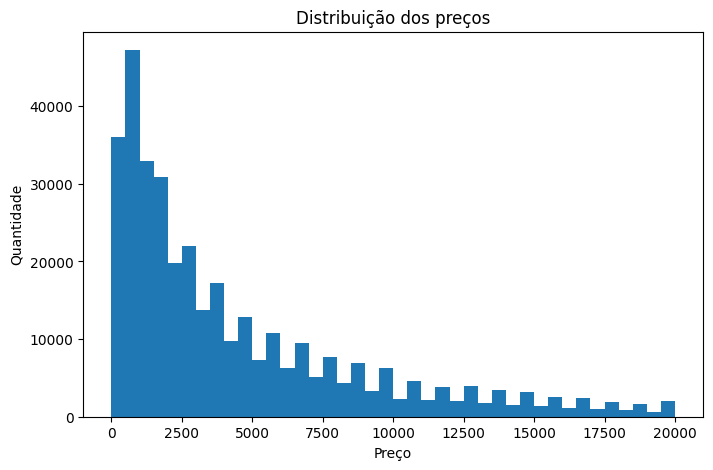

In [10]:
plt.figure(figsize=(8,5))

plt.hist(df['Price'], bins=40)

plt.title('Distribuição dos preços')
plt.xlabel('Preço')
plt.ylabel('Quantidade')

plt.show()

O gráfico permite observar a distribuição da variável alvo e identificar possíveis valores extremos.

## Seleção das variáveis

In [11]:
df = df.drop(['DateCrawled',
              'DateCreated',
              'LastSeen',
              'PostalCode',
              'NumberOfPictures'],
             axis=1)

In [12]:
# Separando alvo e atributos
features = df.drop('Price', axis=1)

target = df['Price']

## Codificando variáveis categóricas

In [13]:
encoder = OrdinalEncoder()

categorical = features.select_dtypes(include='object').columns

features[categorical] = encoder.fit_transform(features[categorical])

Foi utilizado o OrdinalEncoder para converter variáveis categóricas em valores numéricos.

## Divisão treino/teste

In [14]:
features_train, features_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.25,
    random_state=12345
)

In [15]:
# Função para calcular RMSE
def rmse(target, predictions):
    return mean_squared_error(target, predictions, squared=False)

## Treinamento do modelo

In [16]:
# Modelo Linear Regression
model_lr = LinearRegression()

# Tempo de treinamento
start = time.time()

model_lr.fit(features_train, target_train)

train_time_lr = time.time() - start

# Tempo de previsão
start = time.time()

pred_lr = model_lr.predict(features_test)

pred_time_lr = time.time() - start

# RMSE
rmse_lr = rmse(target_test, pred_lr)

print(rmse_lr)

4097.188952273157


A Regressão Linear foi utilizada como modelo de referência por ser simples e extremamente rápida.

## Decision Tree

In [17]:
best_depth = 0
best_rmse = 100000

for depth in range(2,16):

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=12345
    )

    model.fit(features_train,target_train)

    pred = model.predict(features_test)

    score = rmse(target_test,pred)

    if score < best_rmse:

        best_rmse = score
        best_depth = depth

In [18]:
# Treinar o modelo com a melhor profundidade
best_model = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=12345
)

start = time.time()
best_model.fit(features_train, target_train)
train_time_dt = time.time() - start

start = time.time()
pred_dt = best_model.predict(features_test)
pred_time_dt = time.time() - start

rmse_dt = rmse(target_test, pred_dt)

print("Melhor profundidade:", best_depth)
print("RMSE:", rmse_dt)

Melhor profundidade: 13
RMSE: 2072.501369766383


Foram testadas diferentes profundidades da árvore para encontrar o melhor equilíbrio entre desempenho e generalização.

## Random Forest

In [19]:
best_rmse = 100000

for trees in [20,50,100]:

    for depth in [10,15,20]:

        model = RandomForestRegressor(
            n_estimators=trees,
            max_depth=depth,
            random_state=12345
        )

        model.fit(features_train,target_train)

        pred = model.predict(features_test)

        score = rmse(target_test,pred)

        if score < best_rmse:

            best_rmse = score
            best_model = model


start = time.time()
best_model.fit(features_train, target_train)
train_time_rf = time.time() - start

start = time.time()
pred_rf = best_model.predict(features_test)
pred_time_rf = time.time() - start

rmse_rf = rmse(target_test, pred_rf)

print(rmse_rf)

1754.003966548308


O Random Forest combina diversas árvores de decisão, geralmente proporcionando melhor qualidade de previsão.

## LightGBM

In [20]:
model_lgbm = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.1,
    random_state=12345
)

# Treinar o modelo
model_lgbm.fit(features_train, target_train)

# Fazer previsões
pred = model_lgbm.predict(features_test)

start = time.time()
model_lgbm.fit(features_train, target_train)
train_time_lgbm = time.time() - start

start = time.time()
pred_lgbm = model_lgbm.predict(features_test)
pred_time_lgbm = time.time() - start

rmse_lgbm = rmse(target_test, pred_lgbm)

# Calcular o RMSE
print("RMSE:", rmse(target_test, pred))

RMSE: 1800.2033729739046


O LightGBM é um algoritmo baseado em Gradient Boosting conhecido por sua alta velocidade e excelente desempenho em conjuntos de dados grandes.

## CatBoost

In [21]:
model_cat = CatBoostRegressor(
    iterations=300,
    learning_rate=0.1,
    depth=8,
    verbose=False,
    random_state=12345
)

start = time.time()
model_cat.fit(features_train, target_train)
train_time_cat = time.time() - start

start = time.time()
pred_cat = model_cat.predict(features_test)
pred_time_cat = time.time() - start

rmse_cat = rmse(target_test, pred_cat)

print("RMSE:", rmse_cat)
print("Tempo de treinamento:", train_time_cat)
print("Tempo de predição:", pred_time_cat)

RMSE: 1803.3239337096627
Tempo de treinamento: 10.397794723510742
Tempo de predição: 0.010645627975463867


O CatBoost foi desenvolvido para trabalhar eficientemente com variáveis categóricas e costuma apresentar excelente desempenho em problemas tabulares.

## Análise do modelo

In [25]:
# verificar todas as variaveis existentes
%who

CatBoostRegressor	 DecisionTreeRegressor	 LGBMRegressor	 LinearRegression	 OrdinalEncoder	 RandomForestRegressor	 best_depth	 best_model	 best_rmse	 
categorical	 depth	 df	 encoder	 features	 features_test	 features_train	 mean_squared_error	 model	 
model_cat	 model_lgbm	 model_lr	 np	 pd	 plt	 pred	 pred_cat	 pred_dt	 
pred_lgbm	 pred_lr	 pred_rf	 pred_time_cat	 pred_time_dt	 pred_time_lgbm	 pred_time_lr	 pred_time_rf	 results	 
rmse	 rmse_cat	 rmse_dt	 rmse_lgbm	 rmse_lr	 rmse_rf	 score	 start	 target	 
target_test	 target_train	 time	 train_test_split	 train_time_cat	 train_time_dt	 train_time_lgbm	 train_time_lr	 train_time_rf	 
trees	 


In [26]:
#Comparação dos modelos
#Criar uma tabela
results = pd.DataFrame({
    'Modelo': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'LightGBM',
        'CatBoost'
    ],
    'RMSE': [
        rmse_lr,
        rmse_dt,
        rmse_rf,
        rmse_lgbm,
        rmse_cat
    ],
    'Tempo Treinamento': [
        train_time_lr,
        train_time_dt,
        train_time_rf,
        train_time_lgbm,
        train_time_cat
    ],
    'Tempo Predição': [
        pred_time_lr,
        pred_time_dt,
        pred_time_rf,
        pred_time_lgbm,
        pred_time_cat
    ]
})

results

,Modelo,RMSE,Tempo Treinamento,Tempo Predição
0,Linear Regression,4097.188952,0.048335,0.003239
1,Decision Tree,2072.501370,0.625172,0.012308
2,Random Forest,1754.003967,57.815812,2.267354
3,LightGBM,1800.203373,3.674126,0.427313
4,CatBoost,1803.323934,10.397795,0.010646


## Conclusão Final

Com base nos resultados obtidos, é possível analisar o desempenho dos modelos considerando os três critérios do projeto: qualidade da previsão (RMSE), tempo de treinamento e tempo de predição.

| Modelo            |        RMSE | Tempo de Treinamento (s) | Tempo de Predição (s) |
| ----------------- | ----------: | -----------------------: | --------------------: |
| Linear Regression |     4097.19 |                    0.048 |                 0.003 |
| Decision Tree     |     2072.50 |                    0.625 |                 0.012 |
| Random Forest     | **1754.00** |                   57.816 |                 2.267 |
| LightGBM          |     1800.20 |                    3.674 |                 0.427 |
| CatBoost          |     1803.32 |                   10.398 |                 0.011 |

**Regressão Linear**

A Regressão Linear apresentou o maior RMSE (4097,19), indicando que foi o modelo menos preciso entre todos os testados. Esse resultado mostra que um modelo linear não consegue capturar adequadamente a relação entre as características dos veículos e seus preços.

Em compensação, foi o modelo mais rápido, com apenas 0,048 segundos de treinamento e 0,003 segundos para realizar as previsões. Apesar da excelente velocidade, sua baixa precisão faz com que não seja a melhor opção para este problema.

**Árvore de Decisão (Decision Tree)**

A Árvore de Decisão reduziu significativamente o erro, alcançando um RMSE de 2072,50, aproximadamente metade do erro obtido pela Regressão Linear.

O treinamento permaneceu rápido (0,625 s) e a predição também apresentou excelente desempenho (0,012 s). Isso demonstra que modelos não lineares conseguem representar melhor a relação entre as variáveis do conjunto de dados.

**Random Forest**

O Random Forest apresentou o menor RMSE (1754,00), sendo o modelo mais preciso entre todos os avaliados.

Entretanto, essa melhoria na qualidade teve um custo elevado em termos de desempenho computacional. O treinamento levou cerca de 57,8 segundos, muito acima dos demais modelos, e o tempo de predição (2,27 s) também foi o mais alto.

Isso ocorre porque o Random Forest realiza previsões utilizando centenas de árvores de decisão, aumentando o custo computacional.

**LightGBM**

O LightGBM obteve um RMSE de 1800,20, muito próximo ao melhor resultado alcançado pelo Random Forest, com uma diferença inferior a 3%.

Sua principal vantagem está na eficiência computacional: o treinamento foi concluído em apenas 3,67 segundos, aproximadamente 16 vezes mais rápido que o Random Forest. O tempo de predição (0,43 s) também foi significativamente menor.

Esses resultados mostram que o LightGBM oferece um excelente equilíbrio entre precisão e velocidade.

**CatBoost**

O CatBoost apresentou um RMSE de 1803,32, praticamente igual ao do LightGBM.

O treinamento levou cerca de 10,4 segundos, sendo mais lento que o LightGBM, mas ainda muito mais rápido que o Random Forest. Um destaque importante é o tempo de predição (0,011 s), que foi extremamente baixo, ficando próximo ao da Árvore de Decisão e muito inferior ao do Random Forest.

Isso torna o CatBoost uma excelente opção quando é importante realizar previsões rapidamente em um ambiente de produção.

**Conclusão**

Os resultados mostram um claro compromisso entre precisão e desempenho computacional:

A Regressão Linear foi a mais rápida, porém apresentou a pior qualidade de previsão.
A Árvore de Decisão melhorou significativamente a precisão, mantendo tempos de execução reduzidos.
O Random Forest foi o modelo mais preciso, mas exigiu o maior tempo de treinamento e de predição, tornando-se menos eficiente para aplicações em que a velocidade é um fator importante.
O LightGBM apresentou uma precisão muito próxima à do Random Forest, com tempos de treinamento e predição muito menores, oferecendo o melhor equilíbrio entre desempenho e qualidade.
O CatBoost também apresentou excelente precisão e destacou-se pelo baixíssimo tempo de predição, sendo uma alternativa bastante competitiva.

Considerando os objetivos da Rusty Bargain — obter boas previsões sem comprometer o tempo de treinamento e a velocidade de resposta do aplicativo — o LightGBM e o CatBoost representam as soluções mais equilibradas. Se a prioridade for exclusivamente a menor taxa de erro, o Random Forest é a melhor escolha. Porém, se forem considerados conjuntamente qualidade, tempo de treinamento e tempo de predição, o LightGBM se destaca como a opção mais adequada para este projeto.

# Checklist

Digite 'x' para verificar. Em seguida, pressione Shift + Enter.

- [x]  O Jupyter Notebook está aberto
- [x]  O código está livre de erros
- [x]  As células com o código foram organizadas em ordem de execução
- [x]  Os dados foram baixados e preparados
- [x]  Os modelos foram treinados
- [x]  A análise de velocidade e qualidade dos modelos foi realizada